In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("FraudShield AI - Data Exploration")

FraudShield AI - Data Exploration


In [2]:
data_path = "../data/raw/PS_20174392719_1491204439457_log.csv"

df = pd.read_csv(data_path)

print("Dataset successfully loaded!")

Dataset successfully loaded!


In [3]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 6362620
Number of columns: 11


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


In [6]:
df.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


In [7]:
fraud_counts = df["isFraud"].value_counts()

print(fraud_counts)

isFraud
0    6354407
1       8213
Name: count, dtype: int64


In [8]:
fraud_percentage = df["isFraud"].value_counts(normalize=True) * 100

print(fraud_percentage)

isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64


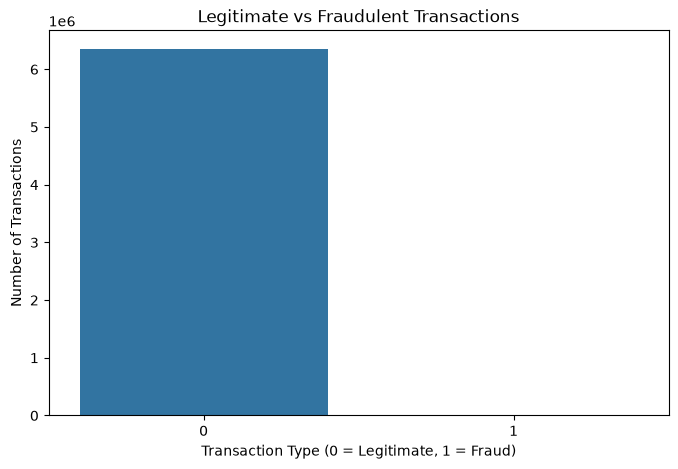

In [9]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="isFraud")

plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Transaction Type (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.show()

In [11]:
missing_values = df.isnull().sum()

print("Missing values per column:")
print(missing_values)

missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

Missing values per column:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64
step              0.0
type              0.0
amount            0.0
nameOrig          0.0
oldbalanceOrg     0.0
newbalanceOrig    0.0
nameDest          0.0
oldbalanceDest    0.0
newbalanceDest    0.0
isFraud           0.0
isFlaggedFraud    0.0
dtype: float64


In [12]:
duplicate_count = df.duplicated().sum()

print("Duplicate records:", duplicate_count)

Duplicate records: 0


In [13]:
transaction_counts = df["type"].value_counts()

print(transaction_counts)

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64


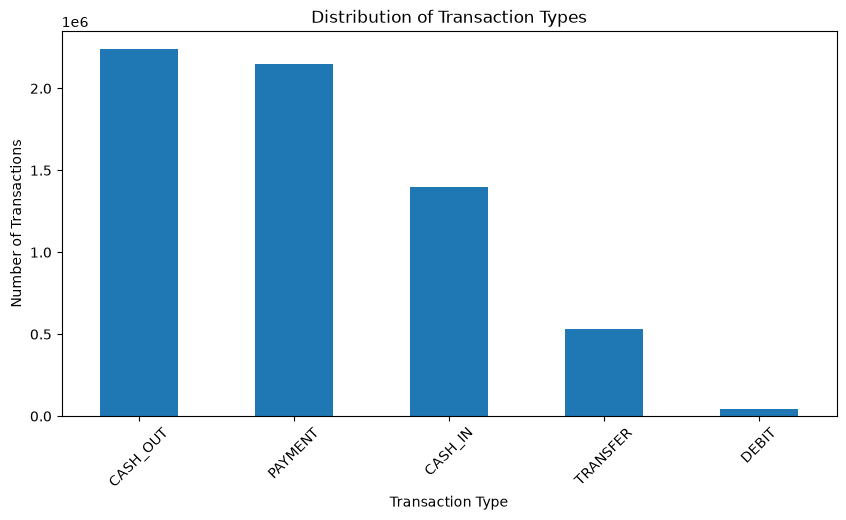

In [14]:
plt.figure(figsize=(10, 5))

transaction_counts.plot(kind="bar")

plt.title("Distribution of Transaction Types")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)

plt.show()

In [15]:
fraud_by_type = df.groupby("type")["isFraud"].sum()

print(fraud_by_type)

type
CASH_IN        0
CASH_OUT    4116
DEBIT          0
PAYMENT        0
TRANSFER    4097
Name: isFraud, dtype: int64


In [16]:
fraud_rate = df.groupby("type")["isFraud"].mean() * 100

print(fraud_rate.sort_values(ascending=False))

type
TRANSFER    0.768799
CASH_OUT    0.183955
CASH_IN     0.000000
DEBIT       0.000000
PAYMENT     0.000000
Name: isFraud, dtype: float64


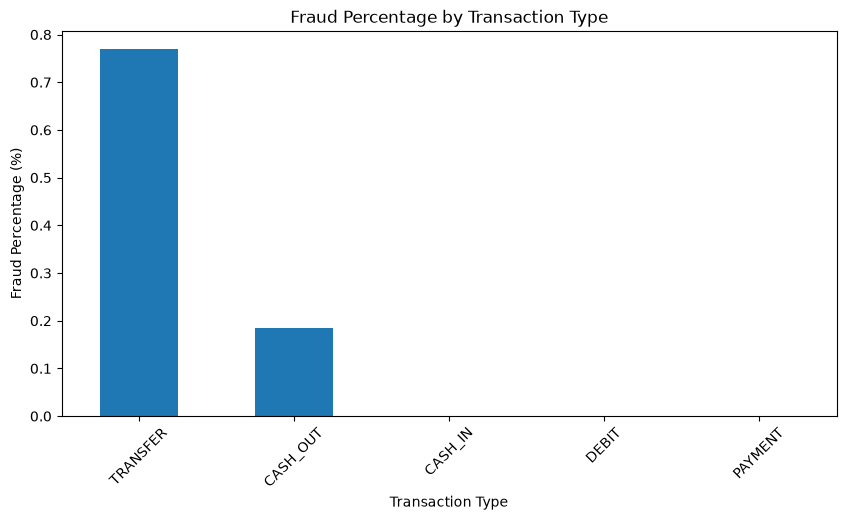

In [17]:
plt.figure(figsize=(10, 5))

fraud_rate.sort_values(ascending=False).plot(kind="bar")

plt.title("Fraud Percentage by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Percentage (%)")
plt.xticks(rotation=45)

plt.show()

In [18]:
average_amount = df.groupby("isFraud")["amount"].mean()

print(average_amount)

isFraud
0    1.781970e+05
1    1.467967e+06
Name: amount, dtype: float64


In [19]:
df.groupby("isFraud")["amount"].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,6354407.0,1.781970e+05,5.962370e+05,0.01,13368.395,74684.72,208364.76,92445516.64
1,8213.0,1.467967e+06,2.404253e+06,0.00,127091.330,441423.44,1517771.48,10000000.00


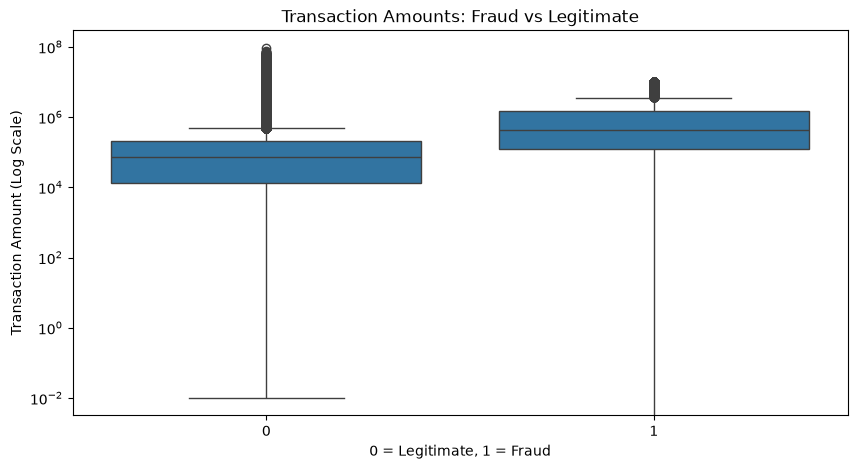

In [5]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="isFraud",
    y="amount"
)

plt.yscale("log")

plt.title("Transaction Amounts: Fraud vs Legitimate")
plt.xlabel("0 = Legitimate, 1 = Fraud")
plt.ylabel("Transaction Amount (Log Scale)")

plt.show()

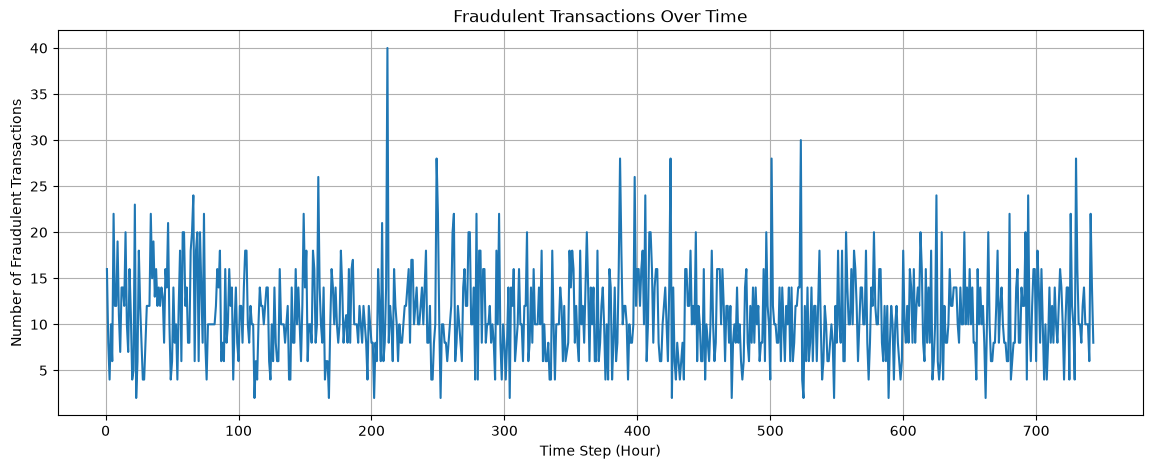

In [6]:
fraud_by_hour = df[df["isFraud"] == 1].groupby("step").size()

plt.figure(figsize=(14, 5))

fraud_by_hour.plot()

plt.title("Fraudulent Transactions Over Time")
plt.xlabel("Time Step (Hour)")
plt.ylabel("Number of Fraudulent Transactions")

plt.grid()
plt.show()

In [ ]:
comparison = pd.crosstab(
    df["isFraud"],
    df["isFlaggedFraud"],
    rownames=["Actual Fraud"],
    colnames=["Flagged by Existing System"]
)

comparison

Flagged by Existing System,0,1
Actual Fraud,,
0,6354407,0
1,8197,16
